# ETSpy Projection Matching Alignment Demo

Projection matching aligns a tilt series by comparing each projection with the corresponding
projection of a reconstruction, and shifting it to match; the reconstruction is then repeated with
the improved shifts. It uses all of the information in the data at once, so it is more accurate
than registering neighbouring projections, and it can reach a small fraction of a pixel.

ETSpy's implementation follows M. Odstr\u010dil *et al.*, Optics Express 27 (2019) 36637
(doi:10.1364/OE.27.036637). This notebook covers:

* Aligning a single slice of a simple 2D object
* Aligning a 3D tilt series with all of its slices, refining the shifts both perpendicular to and
  along the tilt axis
* Measuring the accuracy against the known misalignment
* The main parameters, and why SIRT rather than FBP is used inside the alignment

## Imports

The projection matching routine is in the `projmatch` sub-module of ETSpy:

In [1]:
%matplotlib inline

import time

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs
from scipy import ndimage

import etspy.api as tomo
from etspy import projmatch
from etspy import simulation as sim

tomo.set_log_level("INFO")

## A Single Slice

### Create the Object

A simple object of three squares, blurred slightly to soften the edges:

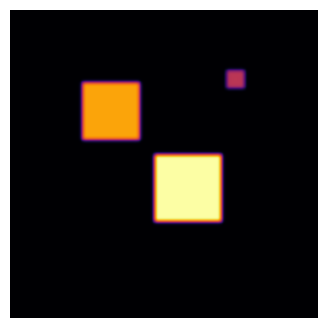

In [2]:
obj = np.zeros([256, 256])
obj[120:176, 120:176] = 10
obj[60:108, 60:108] = 8
obj[50:65, 180:195] = 5
obj = ndimage.gaussian_filter(obj, sigma=1.5)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(obj, cmap="inferno")
ax.axis("off");

### Forward Project and Apply Jitter

`misalign_stack` shifts each projection at random; with `y_only=True`, only perpendicular to the
tilt axis, which is all that a single slice can show. The jitter shows as a ragged sinogram:

INFO | ETSpy | CUDA not detected with Astra (etspy.recon)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


WARNING | Hyperspy | Numba is not installed, falling back to non-accelerated implementation. (hyperspy.decorators:256)


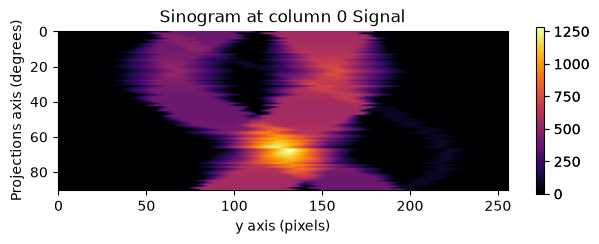

In [3]:
tilt_angles = np.linspace(-90, 90, 91)
sino = sim.create_model_tilt_series(obj[np.newaxis, :, :], angles=tilt_angles)
shifted = sim.misalign_stack(sino, y_only=True)

shifted.extract_sinogram(0).plot(cmap="inferno")

### Projection Matching Alignment

With `nslice` given, only that slice is used and only the Y-shifts are refined. The alignment
starts on a coarse, downsampled copy of the data (`levels`) and refines on finer ones, which makes
it robust to large shifts:

INFO | ETSpy | Binning 8 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 27 iterations (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 4 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 10 iterations (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 2 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 11 iterations (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 1 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 13 iterations (etspy.projmatch.projmatch)


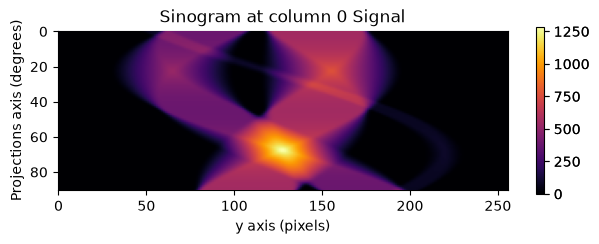

In [4]:
parameters = {
    "levels": [8, 4, 2, 1],
    "iterations": 100,
    "relax": 0.5,
    "recon_algorithm": "SIRT",
}

pm = projmatch.ProjMatch(shifted, nslice=0, cuda=False, params=parameters)
pm.calculate_shifts(show_progressbar=False)
aligned = pm.apply_shifts()

aligned.extract_sinogram(0).plot(cmap="inferno")

INFO | ETSpy | CUDA not detected with Astra (etspy.recon)


INFO | ETSpy | Reconstructing with CPU-based SIRT algorithm (50 iterations) (etspy.recon)


[                                        ] | 0% Completed | 452.51 us

[                                        ] | 0% Completed | 102.04 ms

[                                        ] | 0% Completed | 203.15 ms

[                                        ] | 0% Completed | 304.06 ms

... (50 outputs left out)

[                                        ] | 0% Completed | 2.43 s

[                                        ] | 0% Completed | 2.53 s

[                                        ] | 0% Completed | 2.63 s

[########################################] | 100% Completed | 2.73 s

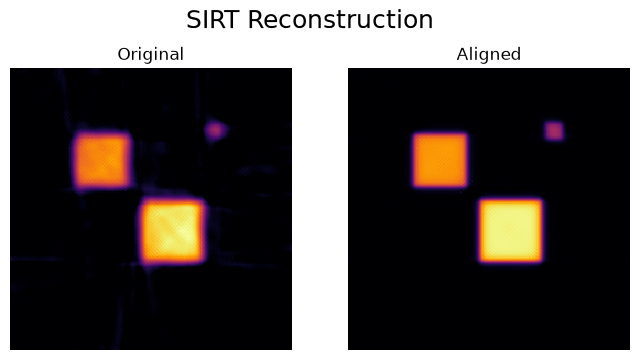

In [5]:
rec_shifted = shifted.reconstruct("SIRT", iterations=50, constrain=True)
rec_aligned = aligned.reconstruct("SIRT", iterations=50, constrain=True)
hs.plot.plot_images(
    [rec_shifted.inav[0], rec_aligned.inav[0]],
    cmap="inferno",
    label=["Original", "Aligned"],
    suptitle="SIRT Reconstruction",
    axes_decor="off",
    colorbar=None,
)
plt.gcf().set_size_inches(8, 4);

## A 3D Tilt Series

### Test Series with Known Misalignment

`create_alignment_test_series` simulates a phantom with features that are sharp in every
direction, misaligns it by random jitter plus drift along both axes, and adds shot noise. It keeps
the true shifts, so the result can be scored (see the [alignment notebook](alignment_in_depth.ipynb)
for the scoring). The tilt axis is not rotated here: projection matching does not refine the axis
direction, which should be corrected first with `tilt_align`.

In [6]:
series = sim.create_alignment_test_series(
    shape=(128, 128), tilts=np.arange(-90, 90, 2.0), tilt_axis=0.0, blur=0.5, dose=200, seed=2
)
tilts = series.misaligned.tilts.data.squeeze()
stack = series.misaligned.remove_background()


def shift_errors(found, truth=series.shifts):
    """RMS errors (px) of the (Y, X) shifts, and the tilt axis offset error (px).

    Y-shifts b cos + c sin (which only move the reconstruction) and a constant X-shift (which
    moves it along the axis) are removed first. A constant Y-shift moves the tilt axis; it is
    reported separately as the axis offset error.
    """
    theta = np.deg2rad(tilts)
    basis = np.array([np.cos(theta), np.sin(theta)]).T
    dy = found[:, 0] - truth[:, 0]
    dy = dy - basis @ np.linalg.lstsq(basis, dy, rcond=None)[0]
    dx = found[:, 1] - truth[:, 1]
    dx = dx - np.median(dx)
    offset = dy.mean()
    return np.sqrt(np.mean((dy - offset) ** 2)), np.sqrt(np.mean(dx**2)), offset

INFO | ETSpy | Removed background of 0.19 to 0.215 from the projections (etspy.base)


### Coarse Alignment First

Projection matching converges best from a reasonable start, so the series is first registered
with StackReg. Registration aligns neighbours with each other but cannot know where the tilt axis
is, so it leaves an axis offset:

In [7]:
reg = stack.stack_register("StackReg")
print("after registration: Y %.2f px, X %.2f px, axis offset %+.2f px" % shift_errors(reg.shifts.data))

after registration: Y 2.27 px, X 0.10 px, axis offset -1.08 px


### Projection Matching on All Slices

By default all of the slices are used, and the shifts are refined both perpendicular to the tilt
axis (Y) and along it (X). Each iteration reconstructs every slice with a few SIRT passes, starting
from the previous reconstruction, reprojects it, and updates the shifts. The shifts found are
added to those of the registered stack:

In [8]:
t0 = time.perf_counter()
pm3d = projmatch.ProjMatch(reg, params={"levels": [4, 2, 1]})
pm3d.calculate_shifts(show_progressbar=False)
aligned3d = pm3d.apply_shifts()
print(f"projection matching took {time.perf_counter() - t0:.0f} s")
print("after projection matching: Y %.2f px, X %.2f px, axis offset %+.2f px"
      % shift_errors(aligned3d.shifts.data))

INFO | ETSpy | Binning 4 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 53 iterations (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 2 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 8 iterations (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 1 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 5 iterations (etspy.projmatch.projmatch)


projection matching took 72 s
after projection matching: Y 0.03 px, X 0.02 px, axis offset -0.01 px


The tilt axis offset is corrected as well: projection matching finds the axis position at which
the reconstruction best explains all of the projections.

### Effect on the Reconstruction

The reconstruction of the ideal series (no misalignment, no noise) is the reference:

INFO | ETSpy | CUDA not detected with Astra (etspy.recon)


INFO | ETSpy | Reconstructing with CPU-based SIRT algorithm (30 iterations) (etspy.recon)


INFO | ETSpy | CUDA not detected with Astra (etspy.recon)


INFO | ETSpy | Reconstructing with CPU-based SIRT algorithm (30 iterations) (etspy.recon)


INFO | ETSpy | Removed background of 0.2 to 0.2 from the projections (etspy.base)


INFO | ETSpy | CUDA not detected with Astra (etspy.recon)


INFO | ETSpy | Reconstructing with CPU-based SIRT algorithm (30 iterations) (etspy.recon)


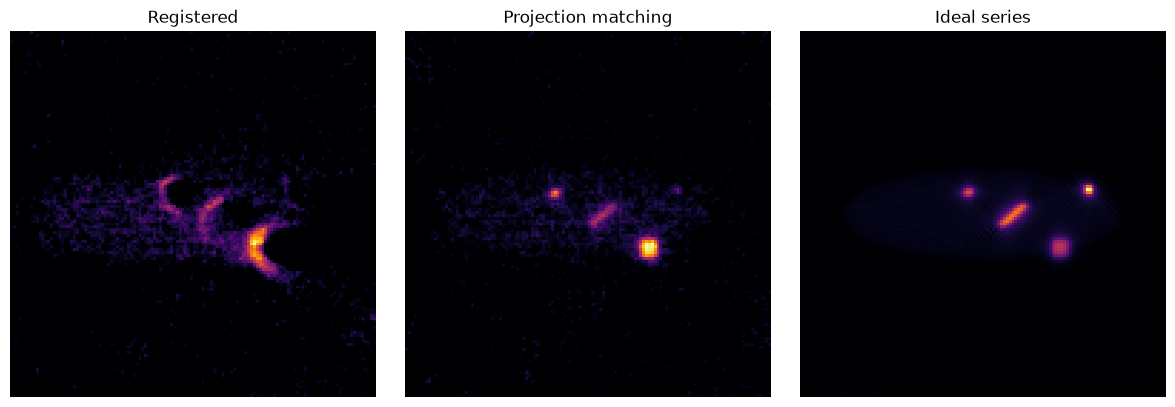

In [9]:
k = 64
recs = [
    reg.reconstruct("SIRT", iterations=30, constrain=True, show_progressbar=False),
    aligned3d.reconstruct("SIRT", iterations=30, constrain=True, show_progressbar=False),
    series.aligned.remove_background().reconstruct(
        "SIRT", iterations=30, constrain=True, show_progressbar=False
    ),
]
hs.plot.plot_images(
    [r.inav[k] for r in recs],
    per_row=3, cmap="inferno", axes_decor="off", colorbar=None,
    label=["Registered", "Projection matching", "Ideal series"],
)
plt.gcf().set_size_inches(12, 4)
plt.tight_layout()

## Parameters

| Parameter | Default | Meaning |
|---|---|---|
| `levels` | `[8, 4, 2, 1]` | Downsampling factors, coarse to fine; start coarser for larger shifts |
| `iterations` | 100 | Maximum iterations per level |
| `minstep` | 0.01 | A level stops when the shift updates are smaller than this (pixels) |
| `relax` | 0.5 | Fraction of each update applied; lower is slower but steadier |
| `recon_algorithm` | `"SIRT"` | Reconstruction inside the loop: `"SIRT"`, `"SART"` or `"FBP"` |
| `recon_iterations` | 10 (SIRT), 5 (SART) | Passes through the data per reconstruction |
| `slices` | all | The slices used, as a `slice` or `(start, stop)`; fewer is faster |
| `align_x` | `True` for several slices | Whether to refine the shifts along the tilt axis |
| `ncores` | 90% of the cores | Threads reconstructing slices on the CPU |

With `cuda=True` the reconstructions run on the GPU.

### Why SIRT and not FBP inside the loop

FBP is several times faster, but its reconstruction from noisy, imperfectly aligned data is itself
noisy and streaky, and those errors feed back into the shifts: it aligns perpendicular to the tilt
axis much less precisely than SIRT, and finds the tilt axis less accurately, as the comparison
below shows on the same series. SIRT smooths the noise, and because each SIRT reconstruction starts from the previous one,
a few passes per iteration are enough. SART is no more precise than SIRT with noisy data, and its
results are not reproducible, because ASTRA orders its projections at random.

In [10]:
pm_fbp = projmatch.ProjMatch(reg, params={"levels": [4, 2, 1], "recon_algorithm": "FBP"})
t0 = time.perf_counter()
pm_fbp.calculate_shifts(show_progressbar=False)
print(f"FBP inside the loop ({time.perf_counter() - t0:.0f} s): "
      "Y %.2f px, X %.2f px, axis offset %+.2f px"
      % shift_errors(reg.shifts.data + pm_fbp.total_shifts))

INFO | ETSpy | Binning 4 (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 2 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 16 iterations (etspy.projmatch.projmatch)


INFO | ETSpy | Binning 1 (etspy.projmatch.projmatch)


INFO | ETSpy | Converged after 3 iterations (etspy.projmatch.projmatch)


FBP inside the loop (21 s): Y 1.23 px, X 0.03 px, axis offset -0.37 px


## Summary

* Register first (`stack_register`), correct the tilt axis direction (`tilt_align`), then refine
  with projection matching
* Use all of the slices, refining both Y and X (the defaults), with SIRT inside the loop
* Projection matching also finds the tilt axis position